# PCA, Factor analaysis and Non Negetive Factorization NMF

Original shape: (178, 13)
Original dimensions: 13

Dimensionality comparison:
         Method  Original Dimensions  Reduced Dimensions  Reconstruction MSE (standardized scale)
            PCA                   13                   2                                 0.445937
Factor Analysis                   13                   2                                 0.481275
            NMF                   13                   2                                 0.523027

PCA explained variance retained: 55.41%
Dimensionality reduction: 84.62%


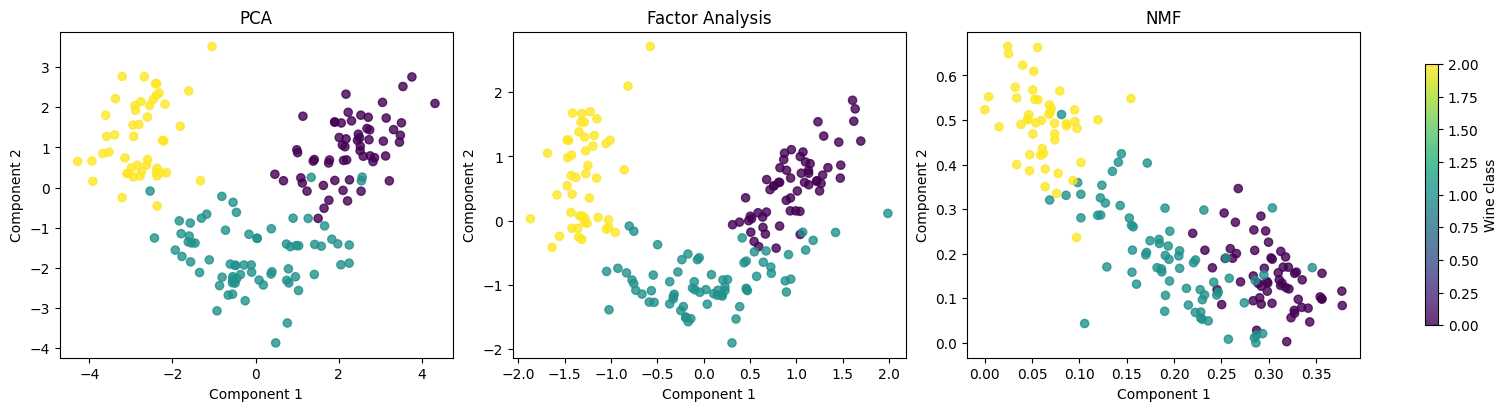


Reduced data shapes:
PCA: (178, 2)
Factor Analysis: (178, 2)
NMF: (178, 2)


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA, FactorAnalysis, NMF
from sklearn.metrics import mean_squared_error
# 1. LOAD DATASET
data = load_wine()
X = data.data
feature_names = data.feature_names
print("Original shape:", X.shape)
print("Original dimensions:", X.shape[1])
# Standardize features for PCA and Factor Analysis
standard_scaler = StandardScaler()
X_scaled = standard_scaler.fit_transform(X)
minmax_scaler = MinMaxScaler()
X_nonnegative = minmax_scaler.fit_transform(X)
k = 2
# 2. PCA
pca = PCA(n_components=k)
X_pca = pca.fit_transform(X_scaled)
X_pca_reconstructed = pca.inverse_transform(X_pca)

pca_mse = mean_squared_error(
    X_scaled, X_pca_reconstructed
)
explained_variance = (
    pca.explained_variance_ratio_.sum() * 100
)
# 3. FACTOR ANALYSIS
fa = FactorAnalysis(
    n_components=k,
    random_state=42
)

X_fa = fa.fit_transform(X_scaled)
X_fa_reconstructed = (
    X_fa @ fa.components_ + fa.mean_
)

fa_mse = mean_squared_error(
    X_scaled, X_fa_reconstructed
)
# 4. NON-NEGATIVE MATRIX FACTORIZATION (NMF)
nmf = NMF(
    n_components=k,
    init="nndsvda",
    max_iter=2000,
    random_state=42
)
# Factorization
W = nmf.fit_transform(X_nonnegative)
H = nmf.components_

X_nmf = W
X_nmf_reconstructed = W @ H
# Convert reconstruction to original feature scale
X_nmf_original = minmax_scaler.inverse_transform(
    X_nmf_reconstructed
)
# Convert to standardized scale for fair MSE comparison
X_nmf_standardized = standard_scaler.transform(
    X_nmf_original
)
nmf_mse = mean_squared_error(
    X_scaled, X_nmf_standardized
)
# 5. DIMENSIONALITY AND ERROR COMPARISON
results = pd.DataFrame({
    "Method": [
        "PCA",
        "Factor Analysis",
        "NMF"
    ],
    "Original Dimensions": [
        X.shape[1]
    ] * 3,
    "Reduced Dimensions": [
        X_pca.shape[1],
        X_fa.shape[1],
        X_nmf.shape[1]
    ],
    "Reconstruction MSE (standardized scale)": [
        pca_mse,
        fa_mse,
        nmf_mse
    ]
})
print("\nDimensionality comparison:")
print(results.to_string(index=False))
print(
    f"\nPCA explained variance retained: "
    f"{explained_variance:.2f}%"
)
print(
    f"Dimensionality reduction: "
    f"{(1 - k / X.shape[1]) * 100:.2f}%"
)
# 6. VISUALIZE REDUCED DATA
reduced_data = [
    (X_pca, "PCA"),
    (X_fa, "Factor Analysis"),
    (X_nmf, "NMF")
]
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4),
    constrained_layout=True
)
for ax, (Z, title) in zip(axes, reduced_data):
    scatter = ax.scatter(
        Z[:, 0],
        Z[:, 1],
        c=data.target,
        cmap="viridis",
        alpha=0.8,
        s=35
    )
    ax.set_title(title)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
fig.colorbar(
    scatter,
    ax=axes.tolist(),
    label="Wine class",
    shrink=0.8
)
plt.show()
print("\nReduced data shapes:")
print("PCA:", X_pca.shape)
print("Factor Analysis:", X_fa.shape)
print("NMF:", X_nmf.shape)